In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("dataset_dummy_deteksi_kebakaran_2000.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (2000, 8)


,mq2_value,temperature_c,humidity_percent,fire_confidence,smoke_confidence,fire_detected,smoke_detected,label
0,130,31.68,68.51,0.062,0.079,0,0,Normal
1,342,39.69,50.25,0.244,0.272,0,1,Peringatan
2,196,27.85,54.60,0.031,0.059,0,0,Normal
3,165,27.66,61.64,0.077,0.069,0,0,Normal
4,771,43.75,37.72,0.856,0.841,1,1,Kebakaran


In [4]:
print("Informasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe())

print("\nJumlah missing values:")
display(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

print("\nDistribusi label:")
display(df["label"].value_counts())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mq2_value         2000 non-null   int64  
 1   temperature_c     2000 non-null   float64
 2   humidity_percent  2000 non-null   float64
 3   fire_confidence   2000 non-null   float64
 4   smoke_confidence  2000 non-null   float64
 5   fire_detected     2000 non-null   int64  
 6   smoke_detected    2000 non-null   int64  
 7   label             2000 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 125.1 KB

Statistik deskriptif:


,mq2_value,temperature_c,humidity_percent,fire_confidence,smoke_confidence,fire_detected,smoke_detected
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,336.793000,34.50996,55.593025,0.222173,0.280892,0.250000,0.387500
std,221.855473,10.10078,11.999820,0.282848,0.302201,0.433121,0.487301
min,1.000000,20.60000,10.000000,0.000000,0.000000,0.000000,0.000000
25%,158.000000,28.12000,48.600000,0.034000,0.048000,0.000000,0.000000
50%,244.500000,30.62500,57.110000,0.069000,0.092000,0.000000,0.000000
75%,479.000000,36.56250,63.815000,0.271250,0.570250,0.250000,1.000000
max,1023.000000,76.65000,94.210000,0.989000,0.990000,1.000000,1.000000



Jumlah missing values:


mq2_value           0
temperature_c       0
humidity_percent    0
fire_confidence     0
smoke_confidence    0
fire_detected       0
smoke_detected      0
label               0
dtype: int64


Jumlah data duplikat: 0

Distribusi label:


label
Normal        1000
Peringatan     600
Kebakaran      400
Name: count, dtype: int64

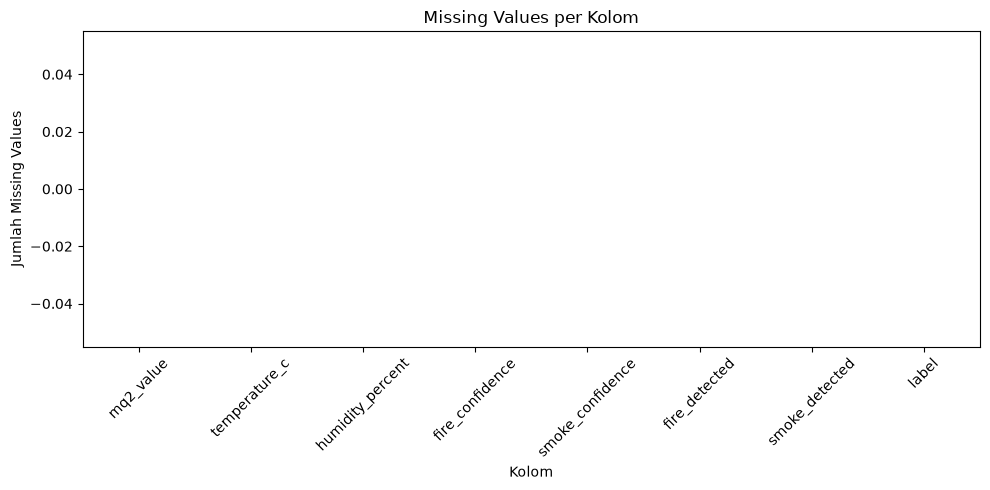

In [5]:
missing = df.isnull().sum()

plt.figure(figsize=(10, 5))
missing.plot(kind="bar")
plt.title("Missing Values per Kolom")
plt.xlabel("Kolom")
plt.ylabel("Jumlah Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
df_clean = df.copy()

numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns.tolist()

if numeric_cols:
    imputer_num = SimpleImputer(strategy="median")
    df_clean[numeric_cols] = imputer_num.fit_transform(df_clean[numeric_cols])

if categorical_cols:
    imputer_cat = SimpleImputer(strategy="most_frequent")
    df_clean[categorical_cols] = imputer_cat.fit_transform(df_clean[categorical_cols])

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Ukuran sebelum cleaning:", df.shape)
print("Ukuran setelah cleaning:", df_clean.shape)
print("\nMissing values setelah cleaning:")
display(df_clean.isnull().sum())

Ukuran sebelum cleaning: (2000, 8)
Ukuran setelah cleaning: (2000, 8)

Missing values setelah cleaning:


mq2_value           0
temperature_c       0
humidity_percent    0
fire_confidence     0
smoke_confidence    0
fire_detected       0
smoke_detected      0
label               0
dtype: int64

In [8]:
df_clean = df.copy()

numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns.tolist()

if numeric_cols:
    imputer_num = SimpleImputer(strategy="median")
    df_clean[numeric_cols] = imputer_num.fit_transform(df_clean[numeric_cols])

if categorical_cols:
    imputer_cat = SimpleImputer(strategy="most_frequent")
    df_clean[categorical_cols] = imputer_cat.fit_transform(df_clean[categorical_cols])

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Ukuran sebelum cleaning:", df.shape)
print("Ukuran setelah cleaning:", df_clean.shape)
print("\nMissing values setelah cleaning:")
display(df_clean.isnull().sum())

Ukuran sebelum cleaning: (2000, 8)
Ukuran setelah cleaning: (2000, 8)

Missing values setelah cleaning:


mq2_value           0
temperature_c       0
humidity_percent    0
fire_confidence     0
smoke_confidence    0
fire_detected       0
smoke_detected      0
label               0
dtype: int64

In [9]:
sensor_cols = [
    "mq2_value",
    "temperature_c",
    "humidity_percent"
]

Q1 = df_clean[sensor_cols].quantile(0.25)
Q3 = df_clean[sensor_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df_clean[sensor_cols] < lower_bound) |
    (df_clean[sensor_cols] > upper_bound)
)

print("Jumlah nilai ekstrem per kolom:")
display(outlier_mask.sum())

df_clean[sensor_cols] = df_clean[sensor_cols].clip(
    lower=lower_bound,
    upper=upper_bound,
    axis=1
)

print("Penanganan nilai ekstrem selesai.")

Jumlah nilai ekstrem per kolom:


mq2_value             8
temperature_c       229
humidity_percent     29
dtype: int64

Penanganan nilai ekstrem selesai.


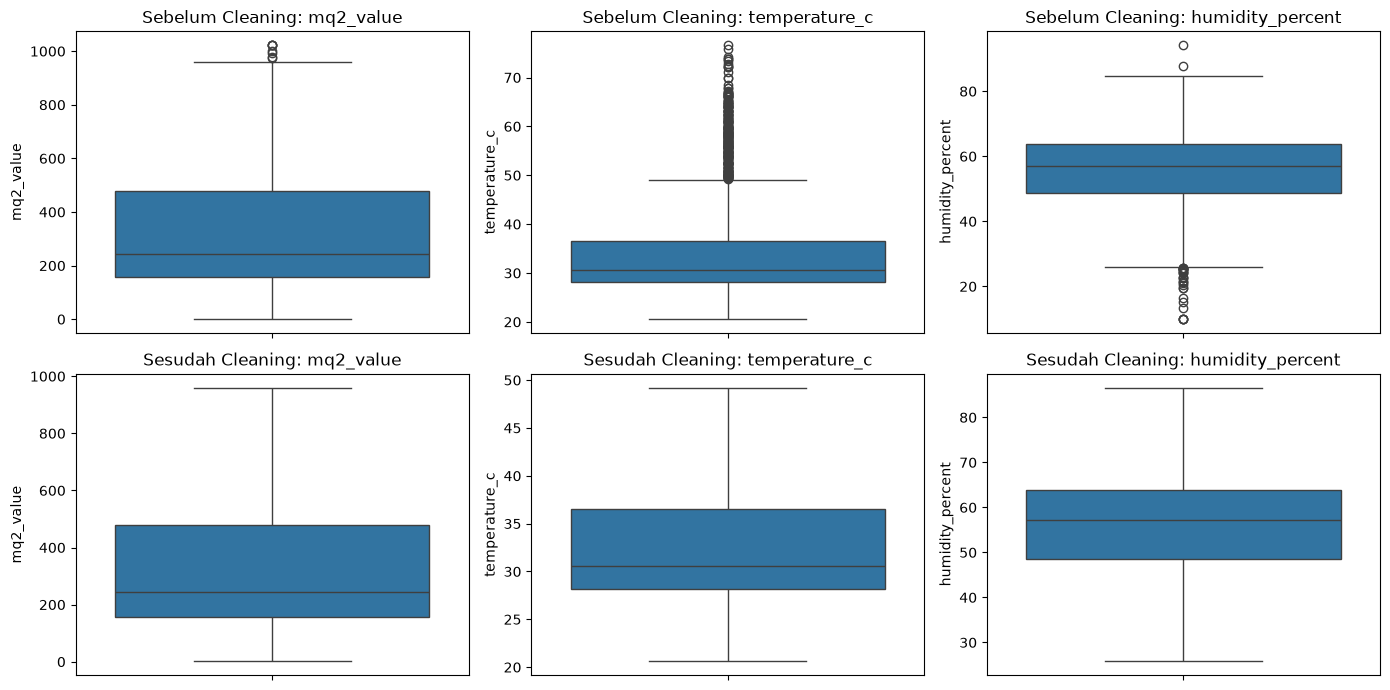

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for i, col in enumerate(sensor_cols):
    sns.boxplot(y=df[col], ax=axes[0, i])
    axes[0, i].set_title(f"Sebelum Cleaning: {col}")

    sns.boxplot(y=df_clean[col], ax=axes[1, i])
    axes[1, i].set_title(f"Sesudah Cleaning: {col}")

plt.tight_layout()
plt.show()

In [11]:
df_clean.to_csv("dataset_kebakaran_cleaned.csv", index=False)

print("Dataset cleaned berhasil disimpan.")
print("Jumlah data:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))

Dataset cleaned berhasil disimpan.
Jumlah data: 2000
Jumlah kolom: 8


In [12]:
X = df_clean.drop(columns=["label"])
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 1600
Jumlah data testing: 400


In [13]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Data training setelah scaling:")
display(X_train_scaled.head())

print("\nRata-rata fitur training setelah scaling:")
display(X_train_scaled.mean().round(3))

print("\nStandar deviasi fitur training setelah scaling:")
display(X_train_scaled.std().round(3))

Data training setelah scaling:


,mq2_value,temperature_c,humidity_percent,fire_confidence,smoke_confidence,fire_detected,smoke_detected
1522,-0.631961,0.258521,0.813242,-0.744145,-0.689870,-0.583124,-0.795395
262,-0.654843,-1.089399,0.543458,-0.680574,-0.646809,-0.583124,-0.795395
1422,-0.718913,-0.722883,0.349042,-0.662916,-0.673308,-0.583124,-0.795395
975,-0.924850,-0.537611,0.401286,-0.694701,-0.636872,-0.583124,-0.795395
1722,-0.581621,-0.764502,-0.462880,-0.560496,-0.732931,-0.583124,-0.795395



Rata-rata fitur training setelah scaling:


mq2_value          -0.0
temperature_c      -0.0
humidity_percent    0.0
fire_confidence    -0.0
smoke_confidence    0.0
fire_detected       0.0
smoke_detected     -0.0
dtype: float64


Standar deviasi fitur training setelah scaling:


mq2_value           1.0
temperature_c       1.0
humidity_percent    1.0
fire_confidence     1.0
smoke_confidence    1.0
fire_detected       1.0
smoke_detected      1.0
dtype: float64

In [14]:
train_scaled = X_train_scaled.copy()
train_scaled["label"] = y_train

test_scaled = X_test_scaled.copy()
test_scaled["label"] = y_test

train_scaled.to_csv("dataset_train_scaled.csv", index=False)
test_scaled.to_csv("dataset_test_scaled.csv", index=False)

print("File berhasil disimpan:")
print("- dataset_train_scaled.csv")
print("- dataset_test_scaled.csv")

File berhasil disimpan:
- dataset_train_scaled.csv
- dataset_test_scaled.csv
